<a href="https://colab.research.google.com/github/abdul-sgf3/EDA-dan-Preprocessing/blob/main/EDA_Adult_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis (EDA) – Adult Census Income

Notebook ini khusus untuk **EDA** dataset `adult.data`. Dataset Adult memiliki 32.561 baris dan 15 kolom. Tujuan EDA adalah memahami struktur data, kualitas data, distribusi variabel, serta hubungan awal fitur dengan target `income`.



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
import os
import urllib.request

FILE_PATH = "adult.data"
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income"
]

# Mengunduh dataset secara otomatis jika belum ada di direktori kerja Colab
if not os.path.exists(FILE_PATH):
    print(f"Mengunduh {FILE_PATH} dari UCI Machine Learning Repository...")
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    urllib.request.urlretrieve(url, FILE_PATH)
    print("Unduhan selesai!")
else:
    print(f"File {FILE_PATH} sudah tersedia.")

df = pd.read_csv(FILE_PATH, header=None, names=columns, skipinitialspace=True)
df.head()

Mengunduh adult.data dari UCI Machine Learning Repository...
Unduhan selesai!


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# 1. Ukuran dan gambaran umum dataset
print("Ukuran dataset:", df.shape)
display(df.head())
display(df.sample(5, random_state=42))
df.info()

Ukuran dataset: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
14160,27,Private,160178,Some-college,10,Divorced,Adm-clerical,Not-in-family,White,Female,0,0,38,United-States,<=50K
27048,45,State-gov,50567,HS-grad,9,Married-civ-spouse,Exec-managerial,Wife,White,Female,0,0,40,United-States,<=50K
28868,29,Private,185908,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,Black,Male,0,0,55,United-States,>50K
5667,30,Private,190040,Bachelors,13,Never-married,Machine-op-inspct,Not-in-family,White,Female,0,0,40,United-States,<=50K
7827,29,Self-emp-not-inc,189346,Some-college,10,Divorced,Craft-repair,Not-in-family,White,Male,2202,0,50,United-States,<=50K


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [4]:
# 2. Statistik deskriptif
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,32561.0,NaN,NaN,NaN,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
workclass,32561,9,Private,22696,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,32561.0,NaN,NaN,NaN,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education,32561,16,HS-grad,10501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_num,32561.0,NaN,NaN,NaN,10.080679,2.57272,1.0,9.0,10.0,12.0,16.0
marital_status,32561,7,Married-civ-spouse,14976,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,32561,15,Prof-specialty,4140,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,32561,6,Husband,13193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,32561,5,White,27816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,32561,2,Male,21790,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# 3. Pemeriksaan missing value
# Pada dataset Adult, nilai hilang ditulis sebagai tanda tanya (?)
df_clean_view = df.replace("?", np.nan)
missing = df_clean_view.isna().sum().sort_values(ascending=False)
missing_percent = (missing / len(df_clean_view) * 100).round(2)
display(pd.DataFrame({"jumlah_missing": missing, "persentase": missing_percent}))

,jumlah_missing,persentase
occupation,1843,5.66
workclass,1836,5.64
native_country,583,1.79
fnlwgt,0,0.00
education,0,0.00
education_num,0,0.00
age,0,0.00
marital_status,0,0.00
relationship,0,0.00
sex,0,0.00


In [6]:
# 4. Pemeriksaan data duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 24


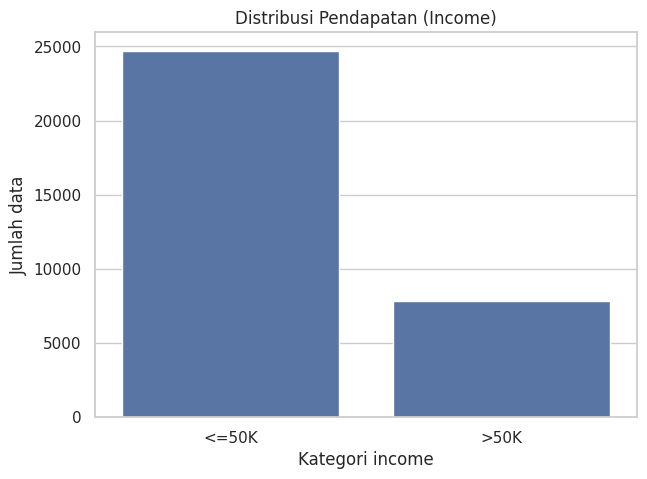

,count
income,
<=50K,24720
>50K,7841


,proportion
income,
<=50K,75.92
>50K,24.08


In [7]:
# 5. Distribusi target income
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="income", order=df["income"].value_counts().index)
plt.title("Distribusi Pendapatan (Income)")
plt.xlabel("Kategori income")
plt.ylabel("Jumlah data")
plt.show()

display(df["income"].value_counts())
display((df["income"].value_counts(normalize=True) * 100).round(2))

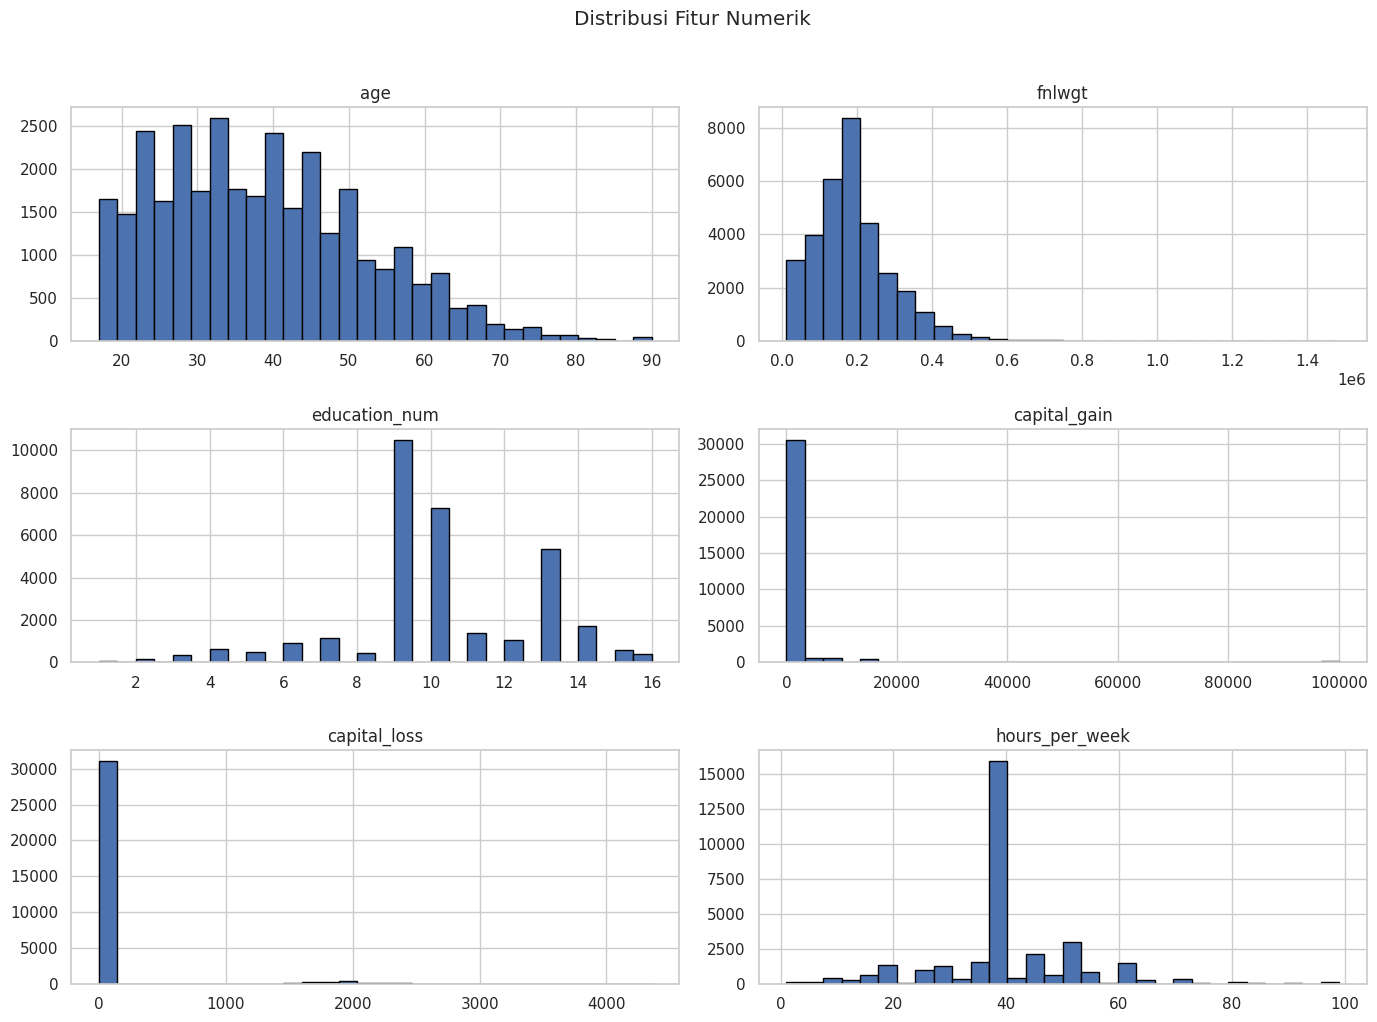

In [8]:
# 6. Distribusi fitur numerik
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(14, 10), bins=30, edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

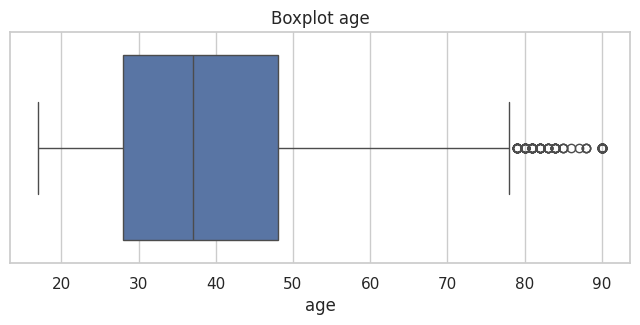

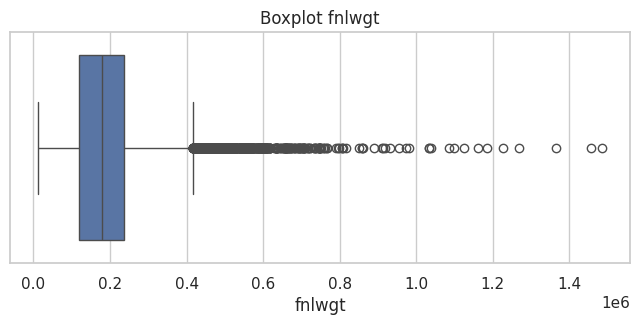

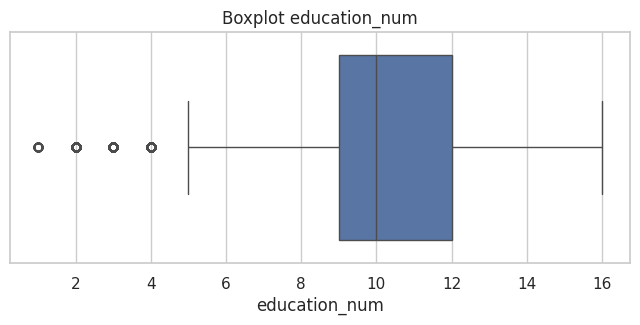

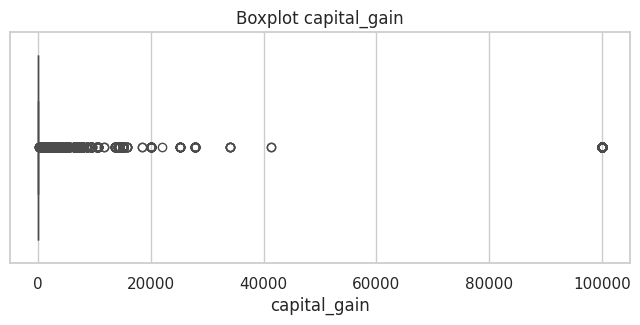

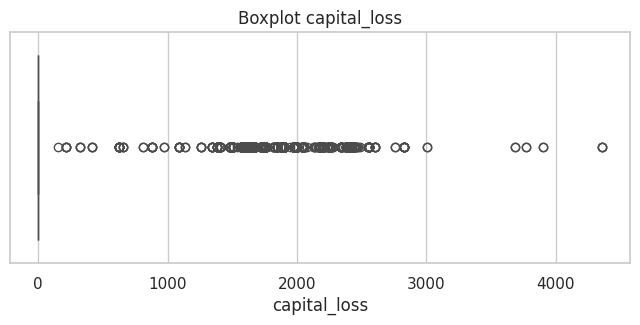

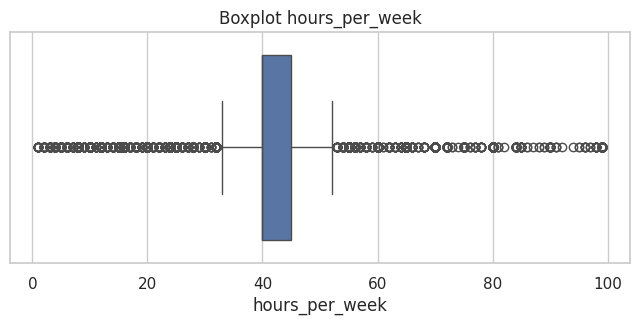

In [9]:
# 7. Boxplot fitur numerik untuk melihat sebaran dan kemungkinan outlier
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot {col}")
    plt.show()

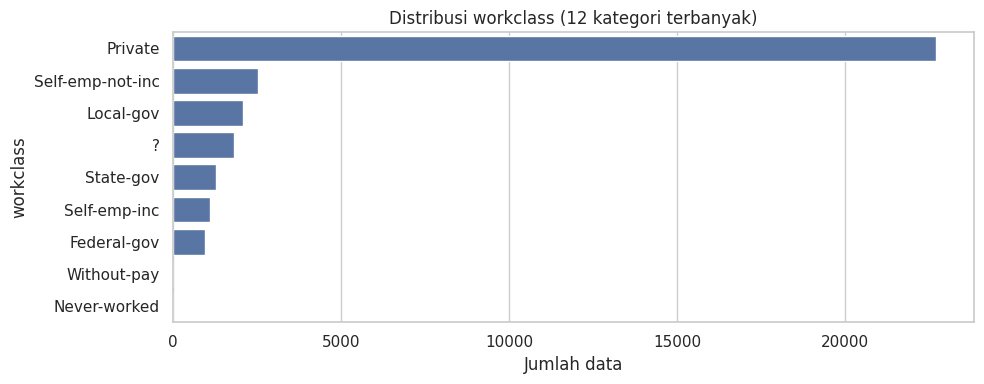

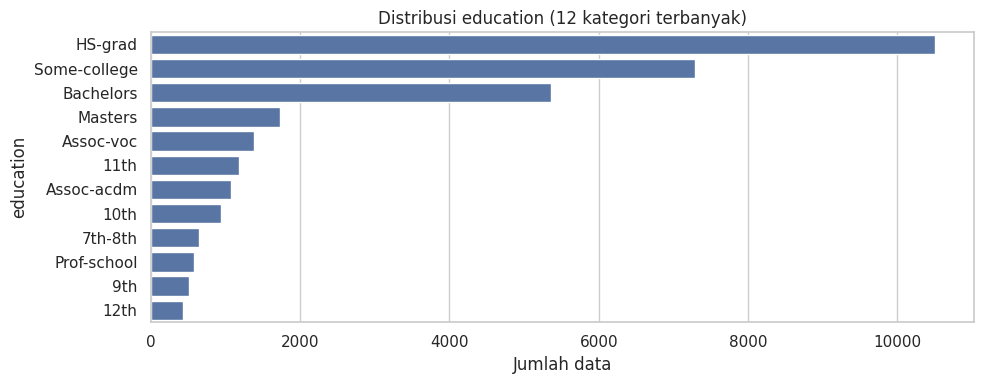

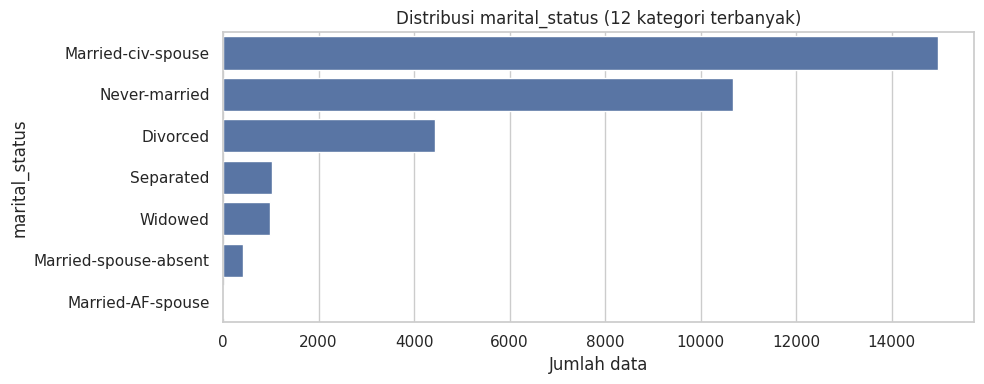

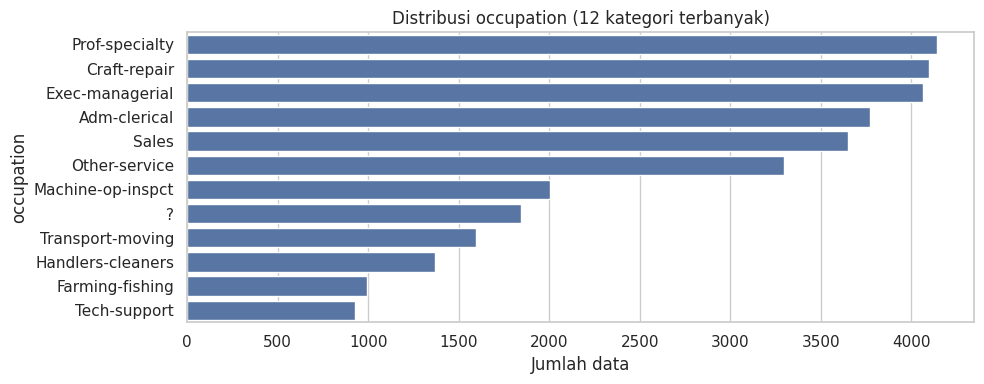

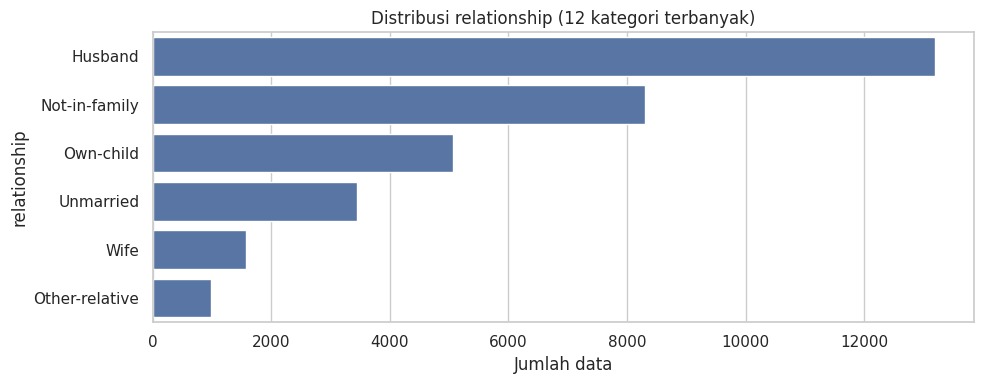

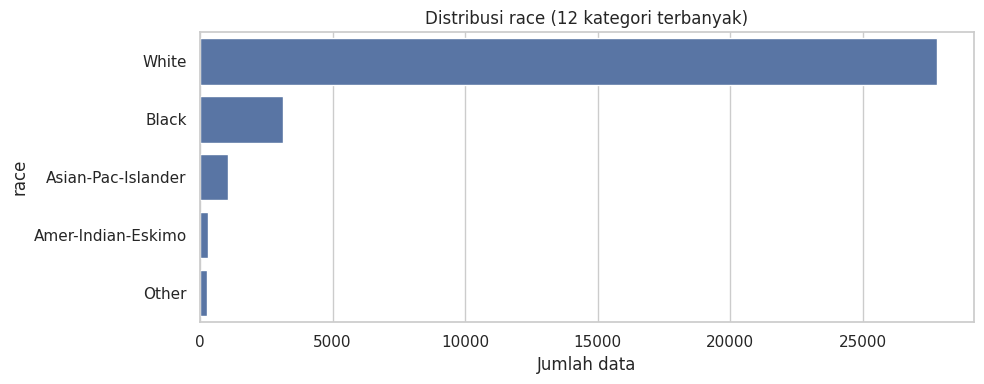

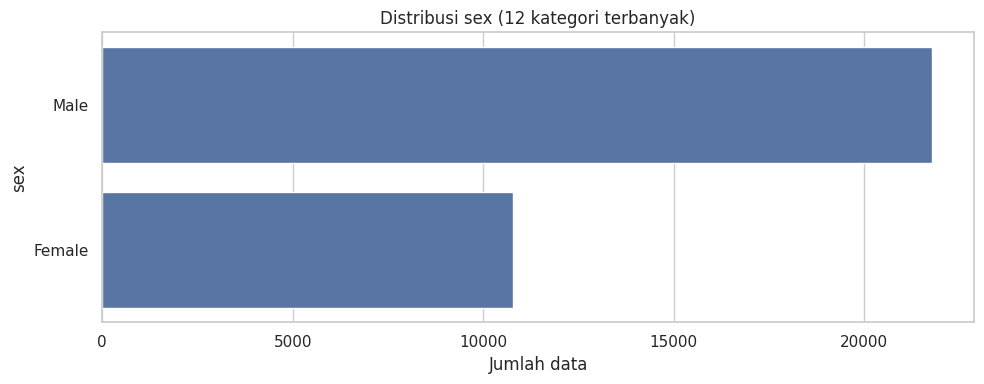

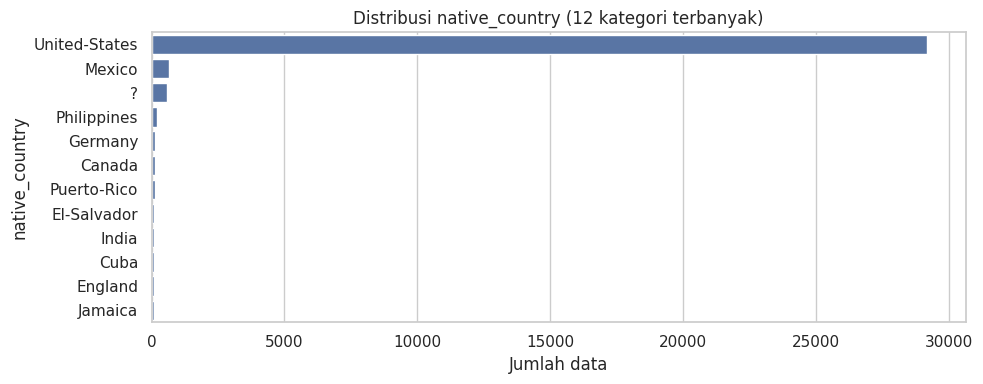

In [10]:
# 8. Distribusi beberapa fitur kategorikal
categorical_cols = df.select_dtypes(include="object").columns.drop("income").tolist()

for col in categorical_cols:
    plt.figure(figsize=(10, 4))
    order = df[col].value_counts().head(12).index
    sns.countplot(data=df, y=col, order=order)
    plt.title(f"Distribusi {col} (12 kategori terbanyak)")
    plt.xlabel("Jumlah data")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

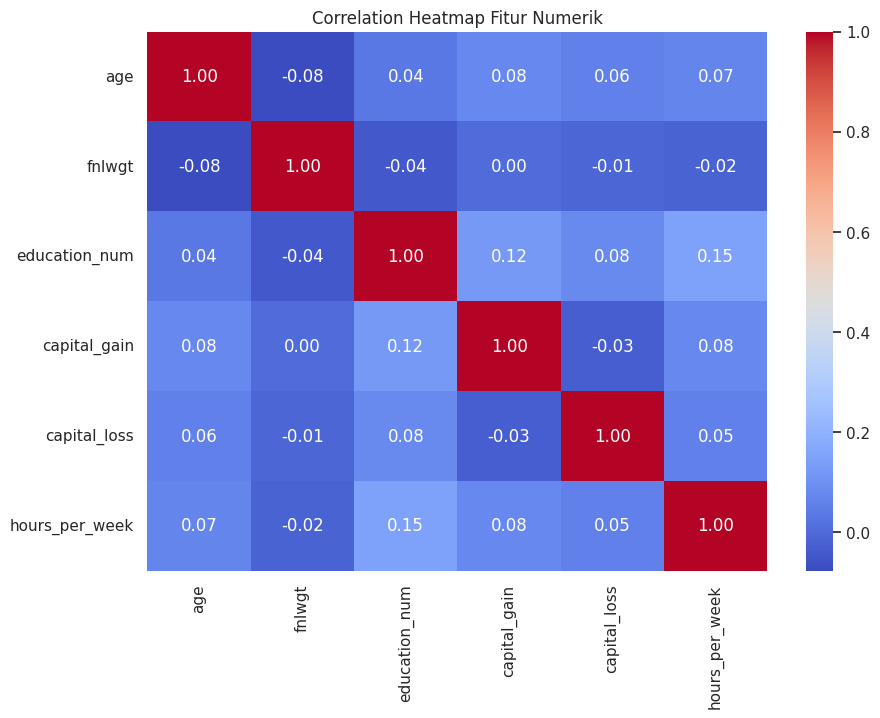

In [11]:
# 9. Korelasi antar fitur numerik
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap Fitur Numerik")
plt.show()

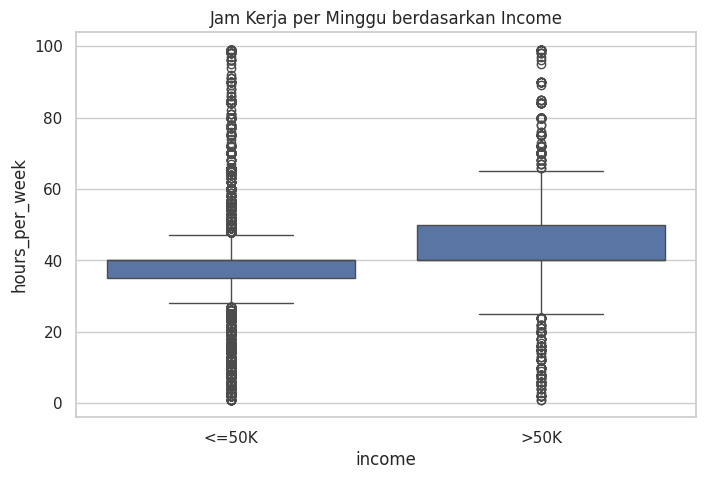

In [12]:
# 10. Perbandingan rata-rata jam kerja berdasarkan income
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="income", y="hours_per_week")
plt.title("Jam Kerja per Minggu berdasarkan Income")
plt.show()

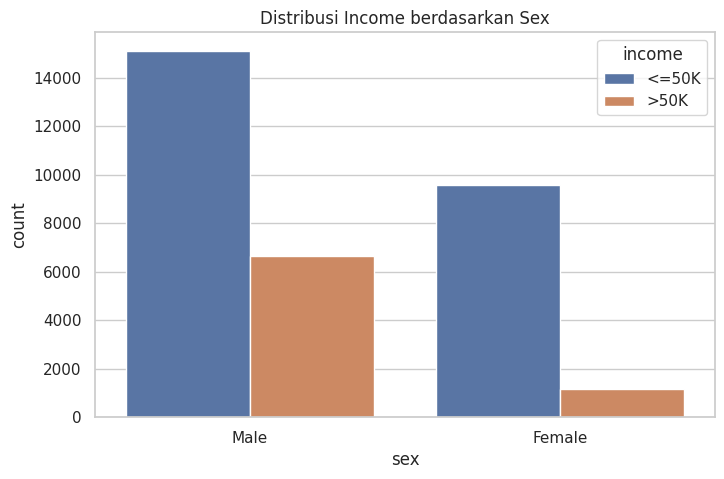

In [13]:
# 11. Pendapatan berdasarkan jenis kelamin
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="sex", hue="income")
plt.title("Distribusi Income berdasarkan Sex")
plt.show()

## Catatan hasil EDA

Setelah menjalankan notebook, rangkum temuan berdasarkan output yang muncul, misalnya:
- Jumlah baris dan kolom dataset.
- Kolom yang memiliki nilai `?`/missing value.
- Apakah terdapat data duplikat.
- Distribusi kelas `income` (seimbang atau tidak).
- Pola menarik dari fitur numerik dan kategorikal.

EDA tidak mengubah dataset sumber; proses pembersihan dan transformasi dilakukan pada notebook preprocessing terpisah.